# Ensemble Learning for Forecasting Weekly Dengue Cases in Sri Lanka

**Dataset:** `srilanka_weekly_data` from the **denguedatahub** R package (v4.1.0) by Thiyanga S. Talagala
(https://cran.r-universe.dev/denguedatahub).

**Goal:** Forecast weekly dengue cases per district and compare:
- **Bagging:** Random Forest
- **Boosting:** XGBoost, LightGBM, CatBoost
- **Stacking:** RF + Boosting + Linear model with a meta-learner
- **Hybrid:** Random Forest + ARIMA


In [1]:
!pip install catboost -q

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

from statsmodels.tsa.arima.model import ARIMA
import joblib

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
print("All libraries loaded")

All libraries loaded


In [3]:
from google.colab import files
uploaded = files.upload()

file_name = list(uploaded.keys())[0]
df = pd.read_excel(file_name)
print("Shape:", df.shape)
df.head(10)

Saving srilanka_weekly_data.xlsx to srilanka_weekly_data (2).xlsx
Shape: (25766, 6)


,year,week,start.date,end.date,district,cases
0,2006,52,12/23/2006,12/29/2006,Colombo,71
1,2006,52,12/23/2006,12/29/2006,Gampaha,12
2,2006,52,12/23/2006,12/29/2006,Kalutara,12
3,2006,52,12/23/2006,12/29/2006,Kandy,20
4,2006,52,12/23/2006,12/29/2006,Matale,4
5,2006,52,12/23/2006,12/29/2006,NuwaraEliya,1
6,2006,52,12/23/2006,12/29/2006,Galle,1
7,2006,52,12/23/2006,12/29/2006,Hambanthota,1
8,2006,52,12/23/2006,12/29/2006,Matara,11
9,2006,52,12/23/2006,12/29/2006,Jaffna,0


In [4]:
print(df.info())
print("\nMissing values:\n", df.isna().sum())
print("\nYears:", df["year"].min(), "to", df["year"].max())
print("Number of districts:", df["district"].nunique())
print("\nNumber of weeks:", df["start.date"].nunique())
df["cases"].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25766 entries, 0 to 25765
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   year        25766 non-null  int64 
 1   week        25766 non-null  int64 
 2   start.date  25766 non-null  object
 3   end.date    25766 non-null  object
 4   district    25766 non-null  object
 5   cases       25766 non-null  int64 
dtypes: int64(3), object(3)
memory usage: 1.2+ MB
None

Missing values:
 year          0
week          0
start.date    0
end.date      0
district      0
cases         0
dtype: int64

Years: 2006 to 2025
Number of districts: 26

Number of weeks: 991


,cases
count,25766.000000
mean,31.167973
std,79.294578
min,0.000000
25%,2.000000
50%,9.000000
75%,29.000000
max,2631.000000


## 1. Data Cleaning


In [5]:
# Rename columns (dots in names are awkward in pandas)
df = df.rename(columns={"start.date": "start_date", "end.date": "end_date"})

# Convert date strings to real dates
df["start_date"] = pd.to_datetime(df["start_date"], format="%m/%d/%Y")
df["end_date"] = pd.to_datetime(df["end_date"], format="%m/%d/%Y")

# Fix district name spellings
df["district"] = df["district"].replace({
    "Kalmune": "Kalmunai",          # Kalmunai RDHS health division
    "NuwaraEliya": "Nuwara Eliya",
    "Hambanthota": "Hambantota"
})

# Check for duplicates and sort by district and time
print("Duplicate rows:", df.duplicated(subset=["district", "start_date"]).sum())
df = df.sort_values(["district", "start_date"]).reset_index(drop=True)

# Check the weekly timeline has no missing weeks
weeks = pd.Series(sorted(df["start_date"].unique()))
print("Date range:", weeks.min().date(), "to", weeks.max().date())
print("Days between consecutive weeks:\n", weeks.diff().dt.days.value_counts())

Duplicate rows: 0
Date range: 2006-12-23 to 2025-12-13
Days between consecutive weeks:
 7.0    988
8.0      1
6.0      1
Name: count, dtype: int64


## 2. Exploratory Data Analysis

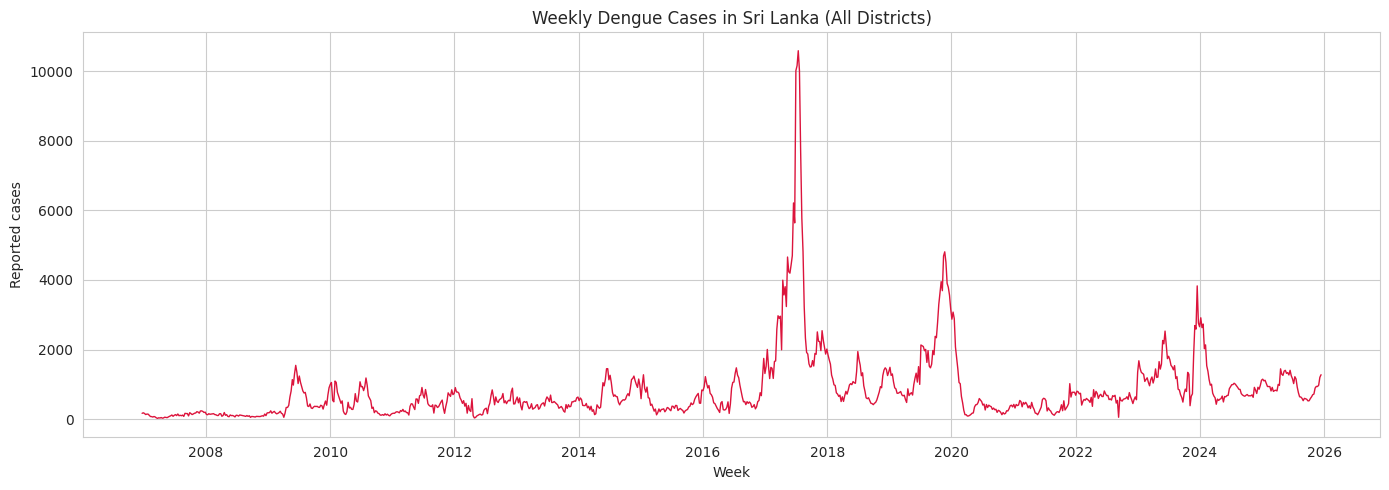

Top 5 worst weeks:
start_date
2017-07-15    10590
2017-07-08    10160
2017-07-01    10018
2017-07-22    10013
2017-07-29     7692
Name: cases, dtype: int64


In [6]:
national = df.groupby("start_date")["cases"].sum()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(national.index, national.values, color="crimson", linewidth=1)
ax.set_title("Weekly Dengue Cases in Sri Lanka (All Districts)")
ax.set_xlabel("Week")
ax.set_ylabel("Reported cases")
plt.tight_layout()
plt.show()

print("Top 5 worst weeks:")
print(national.sort_values(ascending=False).head(5))

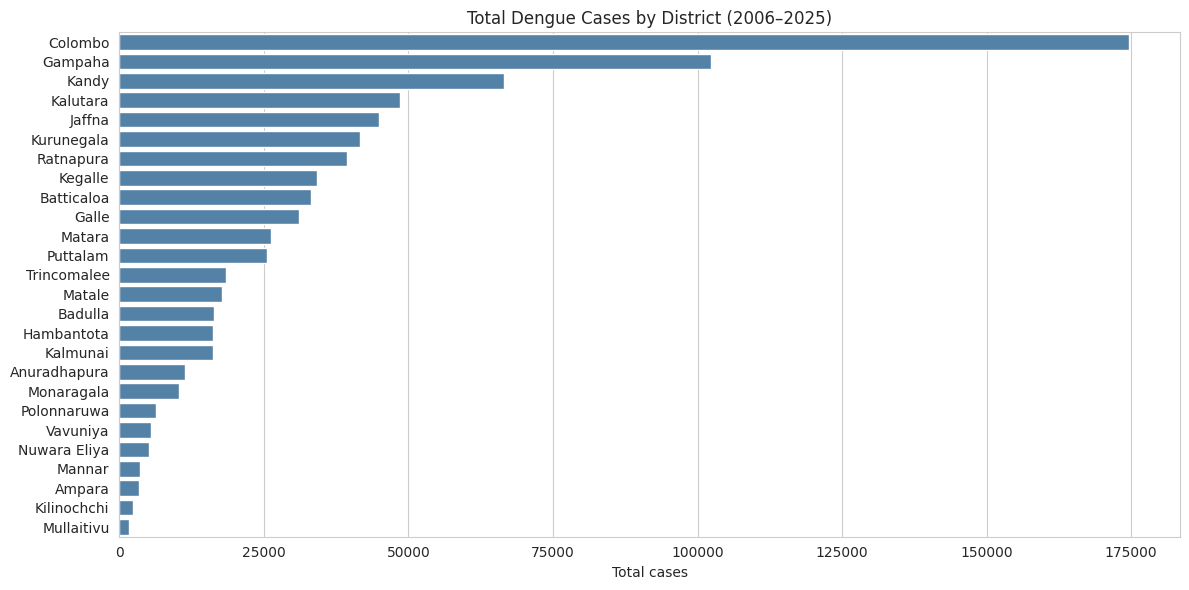

Share of all cases:
district
Colombo     0.218
Gampaha     0.128
Kandy       0.083
Kalutara    0.060
Jaffna      0.056
Name: cases, dtype: float64


In [7]:
district_total = df.groupby("district")["cases"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(x=district_total.values, y=district_total.index, ax=ax, color="steelblue")
ax.set_title("Total Dengue Cases by District (2006–2025)")
ax.set_xlabel("Total cases")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

print("Share of all cases:")
print((district_total / district_total.sum()).head(5).round(3))

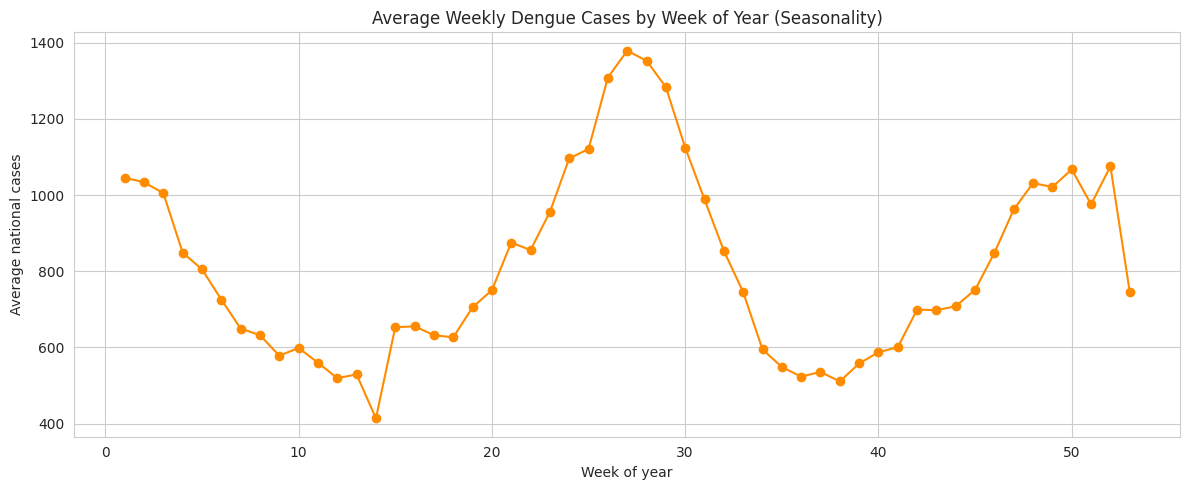

In [8]:
df["week_of_year"] = df["start_date"].dt.isocalendar().week.astype(int)

seasonal = (df.groupby(["year", "week_of_year"])["cases"].sum()
              .groupby("week_of_year").mean())

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(seasonal.index, seasonal.values, marker="o", color="darkorange")
ax.set_title("Average Weekly Dengue Cases by Week of Year (Seasonality)")
ax.set_xlabel("Week of year")
ax.set_ylabel("Average national cases")
plt.tight_layout()
plt.show()

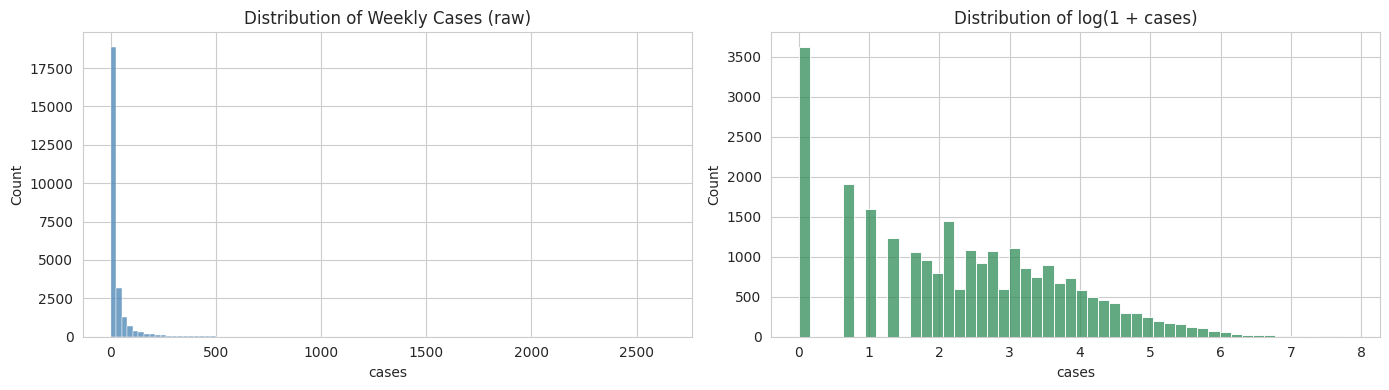

Skewness raw: 10.41 | after log1p: 0.21
Weeks with zero cases: 14.1 %


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["cases"], bins=100, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of Weekly Cases (raw)")
sns.histplot(np.log1p(df["cases"]), bins=50, ax=axes[1], color="seagreen")
axes[1].set_title("Distribution of log(1 + cases)")
plt.tight_layout()
plt.show()

print("Skewness raw:", round(df["cases"].skew(), 2),
      "| after log1p:", round(np.log1p(df["cases"]).skew(), 2))
print("Weeks with zero cases:", round((df["cases"] == 0).mean() * 100, 1), "%")

## 3. Feature Engineering

We forecast **this week's dengue cases in each district** using only information available *before*
that week, which is a one-week-ahead forecast. Features are built separately for each district.

| Feature | Meaning | Why |
|---|---|---|
| lag_1 … lag_4 | Cases 1–4 weeks ago | Dengue spreads gradually, so recent weeks predict the next |
| lag_52 | Cases in the same week last year | Captures yearly monsoon seasonality |
| roll_mean_4, roll_mean_8 | Average of the last 4 and 8 weeks | Smooths out noisy weekly reporting |
| roll_std_4 | Variability over the last 4 weeks | Signals unstable or rising outbreaks |
| trend_1 | lag_1 − lag_2 | Whether cases are rising or falling |
| national_lag_1 | All-island cases last week | Captures country-wide outbreaks |
| week_sin, week_cos | Week of year as a circle | Week 52 and week 1 are close together in time |
| `d_<district>` | One hot district indicators | Each district has a different baseline level |

All case values are **log(1 + cases)** transformed because the target is heavily skewed (see EDA).

In [10]:
data = df.copy()
data["log_cases"] = np.log1p(data["cases"])

# Lag and rolling features, computed separately for each district
grp = data.groupby("district")["log_cases"]
for lag in [1, 2, 3, 4, 52]:
    data[f"lag_{lag}"] = grp.shift(lag)

# shift(1) makes sure rolling windows only use PAST weeks (no data leakage)
data["roll_mean_4"] = grp.transform(lambda s: s.shift(1).rolling(4).mean())
data["roll_mean_8"] = grp.transform(lambda s: s.shift(1).rolling(8).mean())
data["roll_std_4"]  = grp.transform(lambda s: s.shift(1).rolling(4).std())
data["trend_1"] = data["lag_1"] - data["lag_2"]

# Country-wide cases last week
national_log = np.log1p(data.groupby("start_date")["cases"].sum())
data["national_lag_1"] = data["start_date"].map(national_log.shift(1))

# Cyclical encoding of week of year
data["week_sin"] = np.sin(2 * np.pi * data["week_of_year"] / 52)
data["week_cos"] = np.cos(2 * np.pi * data["week_of_year"] / 52)

# The first 52 weeks of each district have no lag_52 value, so drop them
print("Rows before dropping NaN:", len(data))
data = data.dropna().reset_index(drop=True)
print("Rows after dropping NaN:", len(data))
data[["district", "start_date", "cases", "lag_1", "lag_52", "roll_mean_4", "national_lag_1"]].head()

Rows before dropping NaN: 25766
Rows after dropping NaN: 24414


,district,start_date,cases,lag_1,lag_52,roll_mean_4,national_lag_1
0,Ampara,2007-12-22,0,0.0,0.0,0.173287,5.402677
1,Ampara,2007-12-29,0,0.0,0.0,0.173287,5.252273
2,Ampara,2008-01-05,0,0.0,0.0,0.173287,5.303305
3,Ampara,2008-01-12,0,0.0,0.0,0.000000,4.919981
4,Ampara,2008-01-19,0,0.0,0.0,0.000000,4.836282


In [11]:
district_dummies = pd.get_dummies(data["district"], prefix="d", dtype=int)
data = pd.concat([data, district_dummies], axis=1)

BASE_FEATURES = ["lag_1", "lag_2", "lag_3", "lag_4", "lag_52",
                 "roll_mean_4", "roll_mean_8", "roll_std_4", "trend_1",
                 "national_lag_1", "week_sin", "week_cos"]
DISTRICT_FEATURES = list(district_dummies.columns)
FEATURES = BASE_FEATURES + DISTRICT_FEATURES
TARGET = "log_cases"

print("Number of features:", len(FEATURES))

Number of features: 38


## 4. Time-Based Train/Test Split

For time-series data we **cannot shuffle randomly**, because the model would then "see the future".
We train on the past and test on the most recent years:
- **Train:** Dec 2007 – 2022
- **Test:** 2023 – 2025, which includes the large late-2023 outbreak

In [12]:
data = data.sort_values(["start_date", "district"]).reset_index(drop=True)

train = data[data["year"] <= 2022]
test  = data[data["year"] >= 2023]

X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

print(f"Train: {X_train.shape}  {train['start_date'].min().date()} → {train['start_date'].max().date()}")
print(f"Test:  {X_test.shape}  {test['start_date'].min().date()} → {test['start_date'].max().date()}")

Train: (20384, 38)  2007-12-22 → 2022-12-24
Test:  (4030, 38)  2022-12-31 → 2025-12-13


## 5. Evaluation Metrics

This is a regression problem, so we use:
- **MAE (Mean Absolute Error):** the average number of cases the forecast is off by.
- **RMSE (Root Mean Squared Error):** penalises large errors more heavily.
- **R²:** the share of variation in weekly cases that the model explains.

Models are trained on log(1 + cases), and predictions are converted back to real case counts
before scoring, so all metrics are in actual cases.


In [13]:
results = {}       # stores the metrics for every model
predictions = {}   # stores the predictions for comparison charts

def evaluate(name, y_true_log, y_pred_log):
    y_true = np.expm1(y_true_log)
    y_pred = np.clip(np.expm1(y_pred_log), 0, None)   # case counts can't be negative
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    results[name] = {"MAE": mae, "RMSE": rmse, "R2": r2}
    predictions[name] = y_pred
    print(f"{name:<25} MAE: {mae:7.2f}   RMSE: {rmse:7.2f}   R²: {r2:.3f}")

## 6. Hyperparameter Tuning Setup

We tune every model with **GridSearchCV** using **TimeSeriesSplit** (3 folds). Each fold trains on
earlier weeks and validates on later weeks, so tuning never uses future data.
The tuning score is RMSE on the log scale, matching our primary metric.

In [14]:
tscv = TimeSeriesSplit(n_splits=3)
best_params = {}

def tune_and_evaluate(model, param_grid, name):
    search = GridSearchCV(model, param_grid, cv=tscv,
                          scoring="neg_root_mean_squared_error", n_jobs=1)
    search.fit(X_train, y_train)
    best_params[name] = search.best_params_
    print("Best parameters:", search.best_params_)
    best_model = search.best_estimator_
    evaluate(name, y_test, best_model.predict(X_test))
    return best_model

## 7. Bagging: Random Forest

**Bagging** (Bootstrap Aggregating) trains many decision trees, each on a random sample of the data
and a random subset of features, then **averages** their predictions. Averaging reduces variance,
which makes Random Forest robust to noisy weekly reporting.

In [15]:
rf_grid = {
    "n_estimators": [200],
    "max_depth": [None, 20],
    "min_samples_leaf": [2, 5],
    "max_features": [0.5, 1.0]
}

rf_model = tune_and_evaluate(RandomForestRegressor(random_state=42, n_jobs=-1),
                             rf_grid, "Random Forest (Bagging)")

Best parameters: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 5, 'n_estimators': 200}
Random Forest (Bagging)   MAE:   12.10   RMSE:   28.02   R²: 0.837


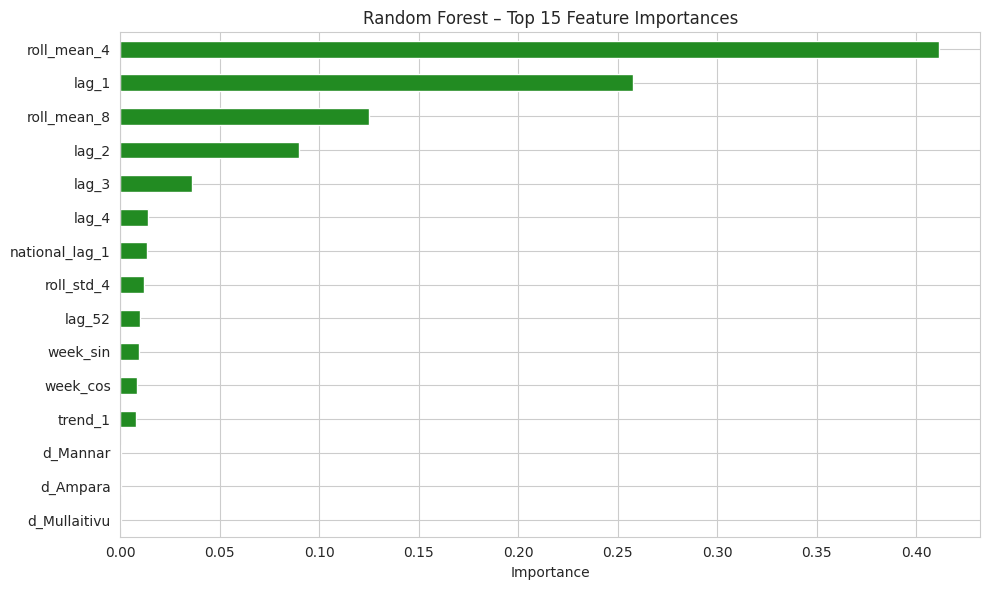

In [16]:
rf_importance = pd.Series(rf_model.feature_importances_, index=FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
rf_importance.head(15).plot(kind="barh", ax=ax, color="forestgreen")
ax.invert_yaxis()
ax.set_title("Random Forest – Top 15 Feature Importances")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

## 8. Boosting: XGBoost vs LightGBM vs CatBoost

**Boosting** builds trees **one after another**, and each new tree corrects the errors of the previous ones.
This reduces bias and usually gives higher accuracy than bagging on tabular data.
- **XGBoost:** regularised gradient boosting that grows trees level by level
- **LightGBM:** grows trees leaf by leaf, so it is very fast on large data
- **CatBoost:** uses symmetric (balanced) trees and ordered boosting, which reduces overfitting

In [17]:
xgb_grid = {
    "n_estimators": [300, 600],
    "learning_rate": [0.03, 0.1],
    "max_depth": [4, 6]
}

xgb_model = tune_and_evaluate(
    XGBRegressor(objective="reg:squarederror", tree_method="hist", random_state=42, n_jobs=-1),
    xgb_grid, "XGBoost (Boosting)")

Best parameters: {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 300}
XGBoost (Boosting)        MAE:   12.00   RMSE:   27.97   R²: 0.837


In [18]:
lgbm_grid = {
    "n_estimators": [300, 600],
    "learning_rate": [0.03, 0.1],
    "num_leaves": [15, 31]
}

lgbm_model = tune_and_evaluate(
    LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1),
    lgbm_grid, "LightGBM (Boosting)")

Best parameters: {'learning_rate': 0.03, 'n_estimators': 300, 'num_leaves': 15}
LightGBM (Boosting)       MAE:   11.95   RMSE:   27.90   R²: 0.838


In [19]:
cat_grid = {
    "iterations": [300, 600],
    "learning_rate": [0.03, 0.1],
    "depth": [4, 6]
}

cat_model = tune_and_evaluate(
    CatBoostRegressor(random_state=42, verbose=0, thread_count=-1),
    cat_grid, "CatBoost (Boosting)")

Best parameters: {'depth': 4, 'iterations': 300, 'learning_rate': 0.03}
CatBoost (Boosting)       MAE:   11.97   RMSE:   28.13   R²: 0.835


## 9. Stacking

**Stacking** combines *different types* of models. Each base model makes predictions, and a
**meta-learner** learns how much to trust each one.

- **Base models:** Random Forest (bagging), LightGBM (boosting) and Ridge Regression (linear)
- **Meta-learner:** Ridge Regression

The idea is that diverse models make *different mistakes*, so combining them can cancel out errors.
We reuse the tuned settings from the Random Forest and LightGBM models above.

In [20]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

stack_model = StackingRegressor(
    estimators=[
        ("rf", rf_model),
        ("lgbm", lgbm_model),
        ("ridge", make_pipeline(StandardScaler(), Ridge(alpha=1.0)))
    ],
    final_estimator=Ridge(alpha=1.0),
    cv=3,
    n_jobs=1
)

stack_model.fit(X_train, y_train)
evaluate("Stacking (RF + LGBM + Ridge)", y_test, stack_model.predict(X_test))

# How much the meta-learner trusts each base model
meta_weights = pd.Series(stack_model.final_estimator_.coef_,
                         index=["Random Forest", "LightGBM", "Ridge"])
print("\nMeta-learner weights:")
print(meta_weights.round(3))

Stacking (RF + LGBM + Ridge) MAE:   11.83   RMSE:   27.98   R²: 0.837

Meta-learner weights:
Random Forest    0.094
LightGBM         0.463
Ridge            0.454
dtype: float64


## 10. Hybrid Model: ARIMA + Random Forest

This hybrid combines a **classical statistical time-series model** with an **ensemble model**:

1. **ARIMA** is fitted separately to each district's weekly series. It captures the *linear* time
   patterns: momentum and short term autocorrelation.
2. ARIMA's errors (**residuals**) contain what it *cannot* capture: non linear effects such as
   seasonal monsoon surges, cross district outbreaks and sudden spikes.
3. A **Random Forest** is trained to predict those residuals using our engineered features.
4. **Final forecast = ARIMA forecast + RF residual correction**

For each district, the ARIMA order is chosen by lowest **AIC** from (1,1,0), (1,1,1) and (2,1,1).
ARIMA is fitted on training data only. Test forecasts are one week ahead, using the same fitted
parameters, so the model never sees future data.

In [21]:
warnings.filterwarnings("ignore")
candidate_orders = [(1, 1, 0), (1, 1, 1), (2, 1, 1)]
arima_rows = []
arima_orders = {}

for district, g in df.sort_values("start_date").groupby("district"):
    series = np.log1p(g["cases"].values.astype(float))
    is_train = (g["year"] <= 2022).values
    train_series = series[is_train]
    test_series  = series[~is_train]

    # Pick the ARIMA order with the lowest AIC (fitted on training data only)
    best_fit, best_order = None, None
    for order in candidate_orders:
        try:
            fit = ARIMA(train_series, order=order).fit()
            if best_fit is None or fit.aic < best_fit.aic:
                best_fit, best_order = fit, order
        except Exception:
            continue
    arima_orders[district] = best_order

    # Add the test weeks WITHOUT refitting, which gives one-week-ahead forecasts
    full_fit = best_fit.append(test_series, refit=False)
    one_step = full_fit.predict()

    arima_rows.append(pd.DataFrame({
        "district": district,
        "start_date": g["start_date"].values,
        "arima_pred": one_step
    }))

arima_df = pd.concat(arima_rows, ignore_index=True)
print("ARIMA order chosen per district:")
print(pd.Series(arima_orders).value_counts())

ARIMA order chosen per district:
(1, 1, 1)    17
(2, 1, 1)     9
Name: count, dtype: int64


In [22]:
data = data.drop(columns=["arima_pred"], errors="ignore").merge(
    arima_df, on=["district", "start_date"], how="left")

train = data[data["year"] <= 2022]
test  = data[data["year"] >= 2023]
print("Missing ARIMA predictions:", data["arima_pred"].isna().sum())

Missing ARIMA predictions: 0


In [23]:
# Step 1: what ARIMA got wrong on the training data
train_resid = y_train.values - train["arima_pred"].values

# Step 2: Random Forest learns to predict those errors (using the tuned RF settings)
hybrid_rf = RandomForestRegressor(**best_params["Random Forest (Bagging)"],
                                  random_state=42, n_jobs=-1)
hybrid_rf.fit(X_train, train_resid)

# Step 3: final forecast = ARIMA + RF correction
hybrid_pred = test["arima_pred"].values + hybrid_rf.predict(X_test)
evaluate("Hybrid (ARIMA + RF)", y_test, hybrid_pred)

Hybrid (ARIMA + RF)       MAE:   12.07   RMSE:   27.71   R²: 0.840


In [24]:
results_df = pd.DataFrame(results).T.sort_values("RMSE").round(3)
results_df

,MAE,RMSE,R2
Hybrid (ARIMA + RF),12.074,27.714,0.840
LightGBM (Boosting),11.953,27.896,0.838
XGBoost (Boosting),12.000,27.974,0.837
Stacking (RF + LGBM + Ridge),11.828,27.983,0.837
Random Forest (Bagging),12.097,28.021,0.837
CatBoost (Boosting),11.965,28.134,0.835


## 11. Model Comparison & Feature Importance

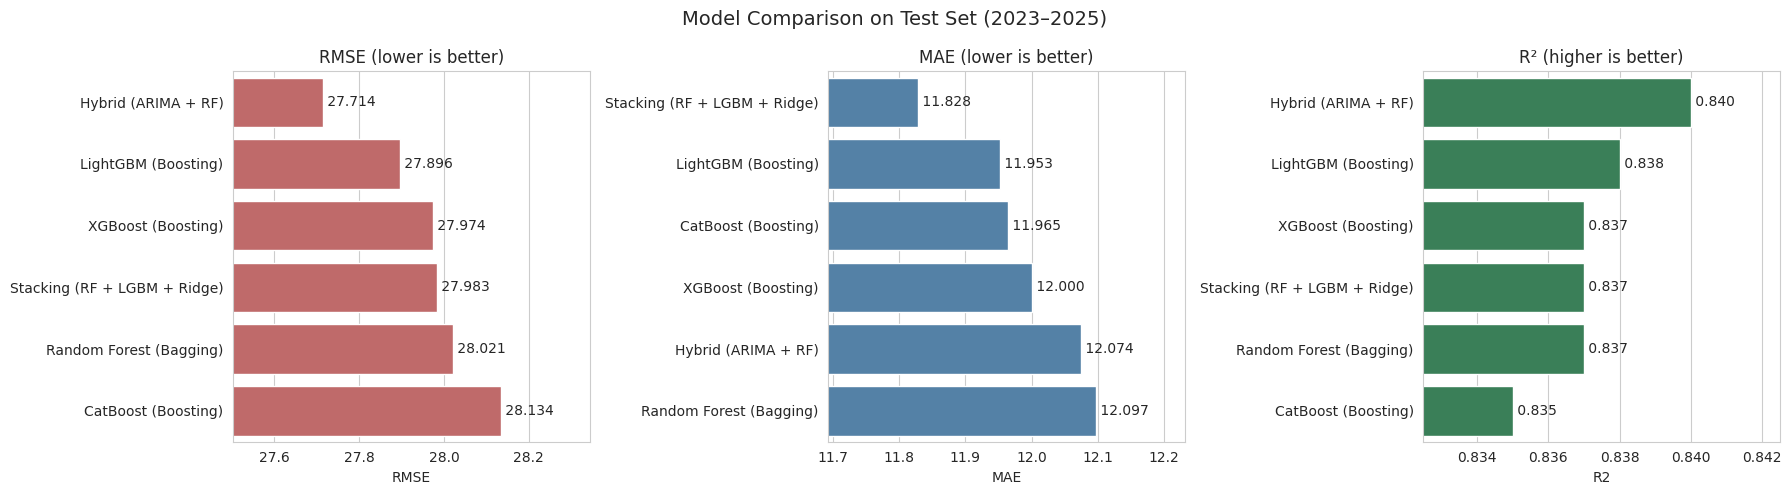

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric, color in zip(axes, ["RMSE", "MAE", "R2"], ["indianred", "steelblue", "seagreen"]):
    order = results_df.sort_values(metric, ascending=(metric != "R2"))
    sns.barplot(x=order[metric], y=order.index, ax=ax, color=color)
    ax.set_title(f"{metric} (lower is better)" if metric != "R2" else "R² (higher is better)")
    ax.set_xlabel(metric)
    ax.set_ylabel("")
    # Zoom in, because the models are close to each other
    lo, hi = order[metric].min(), order[metric].max()
    pad = (hi - lo) * 0.5
    ax.set_xlim(lo - pad, hi + pad)
    for i, v in enumerate(order[metric]):
        ax.text(v, i, f" {v:.3f}", va="center")
plt.suptitle("Model Comparison on Test Set (2023–2025)", fontsize=14)
plt.tight_layout()
plt.show()

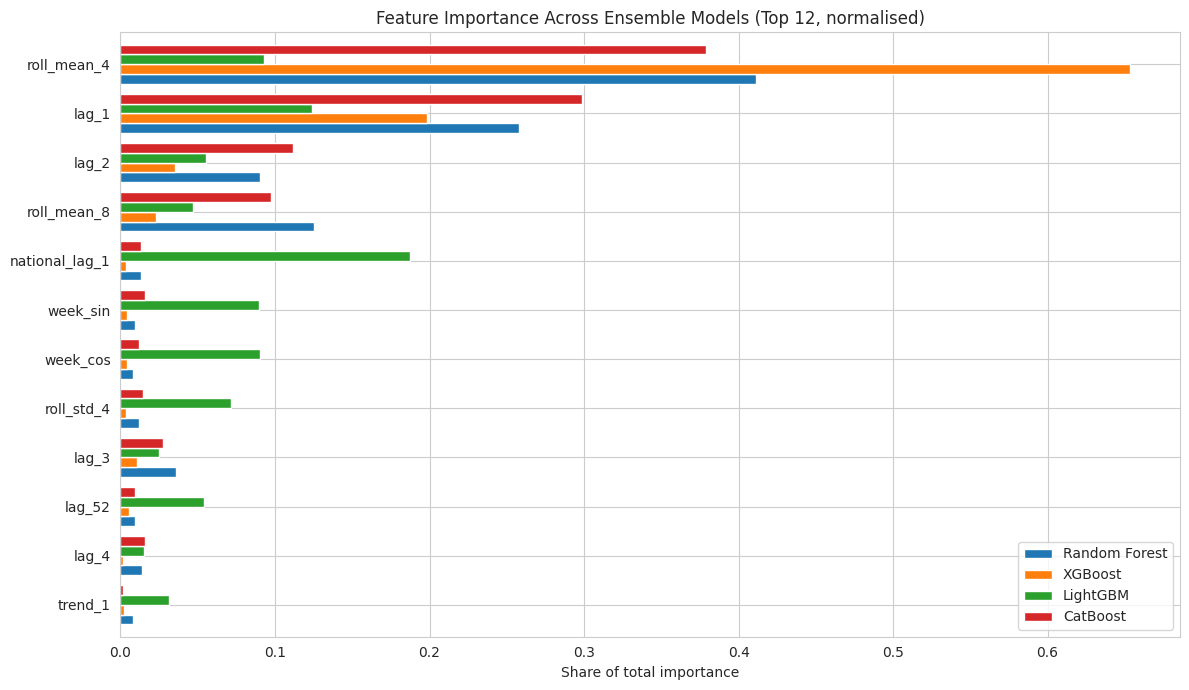

,Random Forest,XGBoost,LightGBM,CatBoost
roll_mean_4,0.412,0.653,0.093,0.379
lag_1,0.258,0.198,0.124,0.298
lag_2,0.090,0.036,0.055,0.111
roll_mean_8,0.125,0.023,0.047,0.097
national_lag_1,0.013,0.004,0.188,0.014
week_sin,0.009,0.004,0.090,0.016
week_cos,0.008,0.004,0.090,0.012
roll_std_4,0.012,0.004,0.071,0.014
lag_3,0.036,0.010,0.025,0.028
lag_52,0.010,0.006,0.054,0.009


In [26]:
importances = pd.DataFrame({
    "Random Forest": rf_model.feature_importances_,
    "XGBoost": xgb_model.feature_importances_,
    "LightGBM": lgbm_model.feature_importances_,
    "CatBoost": cat_model.get_feature_importance(),
}, index=FEATURES)

# Each library measures importance differently, so convert each to a share of 100%
importances = importances / importances.sum()

top = importances.mean(axis=1).sort_values(ascending=False).head(12).index
fig, ax = plt.subplots(figsize=(12, 7))
importances.loc[top].iloc[::-1].plot(kind="barh", ax=ax, width=0.8)
ax.set_title("Feature Importance Across Ensemble Models (Top 12, normalised)")
ax.set_xlabel("Share of total importance")
plt.tight_layout()
plt.show()

importances.loc[top].round(3)

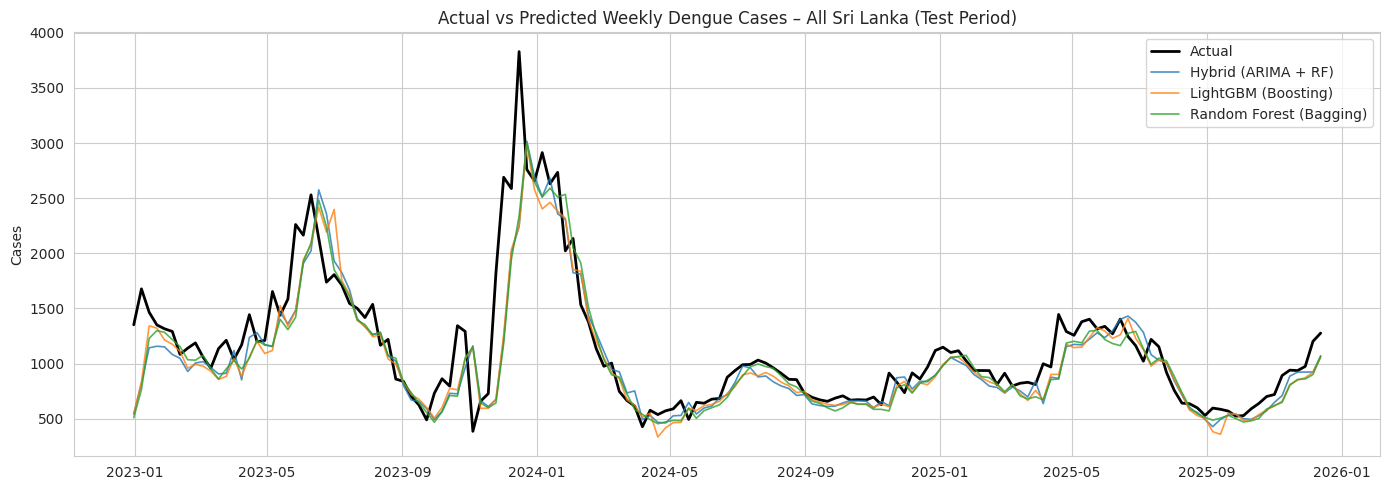

In [27]:
plot_df = test[["start_date"]].copy()
plot_df["Actual"] = np.expm1(y_test.values)
for name in ["Hybrid (ARIMA + RF)", "LightGBM (Boosting)", "Random Forest (Bagging)"]:
    plot_df[name] = predictions[name]

# Add up all districts to get the national picture
national_test = plot_df.groupby("start_date").sum()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(national_test.index, national_test["Actual"], color="black", linewidth=2, label="Actual")
for name in national_test.columns.drop("Actual"):
    ax.plot(national_test.index, national_test[name], linewidth=1.2, alpha=0.8, label=name)
ax.set_title("Actual vs Predicted Weekly Dengue Cases – All Sri Lanka (Test Period)")
ax.set_ylabel("Cases")
ax.legend()
plt.tight_layout()
plt.show()

## 12. Results Interpretation

### 12.1 Final Results (Test Set: 2023–2025)

| Rank | Model | Paradigm | MAE | RMSE | R² |
|---|---|---|---|---|---|
| 1 | Hybrid (ARIMA + RF) | Hybrid | 12.074 | **27.714** | **0.840** |
| 2 | LightGBM | Boosting | 11.953 | 27.896 | 0.838 |
| 3 | XGBoost | Boosting | 12.000 | 27.974 | 0.837 |
| 4 | Stacking (RF + LGBM + Ridge) | Stacking | **11.828** | 27.983 | 0.837 |
| 5 | Random Forest | Bagging | 12.097 | 28.021 | 0.837 |
| 6 | CatBoost | Boosting | 11.965 | 28.134 | 0.835 |

All models explain about **84% of the variation** in weekly district dengue cases, and are off by about
**12 cases per district per week** on average. The gap between the best and worst RMSE is only about **1.5%**.

### 12.2 Why did the Hybrid (ARIMA + RF) perform best?
- **Each district gets its own time-series model.** All the other models learn *one* set of rules shared
  by all 26 districts. ARIMA is fitted separately for each district, so it captures each district's own
  momentum. Colombo's dengue dynamics are very different from Mannar's.
- **Division of labour.** ARIMA handles the linear week to week autocorrelation. The Random Forest then
  only has to learn the non-linear part ARIMA misses, such as monsoon season surges and country wide
  outbreaks. Each model does what it is best at.
- This is why the hybrid gives the best **RMSE**, our primary metric, which penalises large errors in
  outbreak weeks most heavily.

### 12.3 Why did LightGBM perform best among the pure ensembles?
- The feature importance table shows that LightGBM uses a **much wider range of features**. RF, XGBoost and
  CatBoost put **67–85%** of their importance on just `roll_mean_4` and `lag_1` (recent cases). LightGBM
  spreads importance across `national_lag_1` (0.19), `week_sin/cos` (0.18 combined), `roll_std_4` and
  `lag_52`. So it captures **seasonality and national outbreak signals**, not just persistence.
- Its **leaf-wise tree growth** lets it focus splits on the hardest to predict areas (high case weeks).
- Caveat: LightGBM's default importance counts **how often** a feature is used in splits, while the
  others measure **how much error is reduced**, so its importance is naturally more spread out.

### 12.4 Bagging vs Boosting
- **Random Forest (bagging)** averages many independent trees. This reduces variance and gives stable
  forecasts, but the averaging smooths out extreme values, so it slightly **under predicts outbreak peaks**.
- **Boosting (XGBoost, LightGBM)** builds trees one after another to correct previous errors. This reduces
  bias, which is why two of the three boosting models beat Random Forest on RMSE.
- **CatBoost ranked last** on RMSE. Its main advantage, native handling of categorical features, was
  unused because districts were already one hot encoded. Its symmetric (balanced) trees are also more
  constrained, making it more conservative on spikes.

### 12.5 Why did Stacking not win on RMSE?
Stacking achieved the **best MAE (11.83)**: combining models reduces typical errors. However, it did
not beat its best base model on RMSE. Stacking works best when base models make **different** mistakes.
Here, all models rely on the same recent case features, so they **make the same mistakes at the same
time** (all are late at outbreak peaks), and the meta-learner cannot cancel these out.

### 12.6 Common limitation: forecasts lag behind outbreaks
The actual-vs-predicted chart shows that all models follow the real curve closely but **react about one
week late** to sudden rises, for example the late 2023 outbreak. This is because the most important
features are *past* case counts (`roll_mean_4`, `lag_1`). The models detect an outbreak once it has
started, but cannot anticipate it.

### 12.7 Strengths and Limitations of Ensemble Models

**Strengths**
- Capture **non-linear relationships** and feature interactions automatically
- Robust to skewed data and outliers
- Need little feature scaling, and give **feature importance** for interpretability
- Combining models (bagging, boosting, stacking, hybrid) reduces variance and/or bias

**Limitations**
- **Cannot extrapolate.** Tree-based models cannot predict values outside the range seen in training,
  so an outbreak larger than anything in the training data would be under-predicted.
- Less interpretable than a single tree or linear model
- Computationally heavier: tuning took several minutes and the saved Random Forest files are large
- Gains over a single strong model can be small (about 1.5% here), so extra complexity is not always justified

### 12.8 Research Reflection: Tabular vs Image/Text Data
Research consistently shows that **tree-based ensembles remain state of the art for tabular data** like
ours. Tabular features
are each individually meaningful (e.g. `lag_1`), often irregular, and include uninformative features.
Trees handle this well by splitting on one feature at a time.

For **image and text data**, ensembles of trees perform poorly. Meaning there comes from **spatial or
sequential structure**: neighbouring pixels form shapes, and word order forms meaning. A single pixel or
word is not meaningful on its own. **Deep learning** (CNNs for images, Transformers for text) learns these
representations directly from raw data and dominates those domains. Ensemble *ideas* still appear there,
though, for example averaging multiple neural networks, or using boosting on top of embeddings extracted
by a neural network.

### 12.9 Conclusion
For forecasting weekly dengue cases in Sri Lanka, **combining a classical time-series model (ARIMA) with
an ensemble (Random Forest)** gave the most accurate forecasts. Among pure ensembles, **boosting
(LightGBM)** performed best. However, all models were close.

## 13. Saving Models for the Dashboard
All trained models are saved as compressed `.pkl` files, along with the data and results the dashboard needs.

In [28]:
import os
os.makedirs("models", exist_ok=True)

# 1. Trained models (compress=3 keeps each file under GitHub's 100 MB limit)
models_to_save = {
    "random_forest": rf_model,
    "xgboost": xgb_model,
    "lightgbm": lgbm_model,
    "catboost": cat_model,
    "stacking": stack_model,
    "hybrid_rf": hybrid_rf,
}
for name, model in models_to_save.items():
    joblib.dump(model, f"models/{name}.pkl", compress=3)
    print(f"Saved {name}.pkl  ({os.path.getsize(f'models/{name}.pkl') / 1e6:.1f} MB)")

# XGBoost is also saved in its native JSON format, which loads reliably on any OS
xgb_model.save_model("models/xgboost.json")
print("Saved xgboost.json")

# 2. Settings the dashboard needs to rebuild inputs
joblib.dump({
    "FEATURES": FEATURES,
    "BASE_FEATURES": BASE_FEATURES,
    "best_params": best_params,
    "arima_orders": arima_orders,
}, "models/metadata.pkl")

# 3. Results and feature importance (for the comparison pages)
results_df.to_csv("models/results.csv")
importances.to_csv("models/feature_importance.csv")

# 4. Data with features + ARIMA forecasts (for live predictions)
cols = ["district", "start_date", "year", "cases", "log_cases"] + BASE_FEATURES + ["arima_pred"]
data[cols].to_csv("models/dashboard_data.csv", index=False)

# 5. Test-set predictions from every model (for actual-vs-predicted charts)
pred_df = test[["district", "start_date"]].copy()
pred_df["Actual"] = np.expm1(y_test.values)
for name, p in predictions.items():
    pred_df[name] = p
pred_df.to_csv("models/test_predictions.csv", index=False)

print("\nAll files saved")

Saved random_forest.pkl  (20.0 MB)
Saved xgboost.pkl  (0.1 MB)
Saved lightgbm.pkl  (0.2 MB)
Saved catboost.pkl  (0.1 MB)
Saved stacking.pkl  (40.3 MB)
Saved hybrid_rf.pkl  (21.1 MB)
Saved xgboost.json

All files saved


In [29]:
!zip -r -q models.zip models
files.download("models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## AI Usage Acknowledgment

I declare the following use of AI tools:

- **Tool used:** Claud
- **Where and how it was used:**
  - Generating the Python code for data cleaning, feature engineering, model training
    (Random Forest, XGBoost, LightGBM, CatBoost, Stacking, ARIMA + RF hybrid), hyperparameter tuning,
    evaluation and charts
  - Debugging errors encountered while running the notebook
  - Generating the Streamlit dashboard code
